# 02C — Person-ID pilot using YOLO predict + plain-Python IoU association

Your tests show ordinary `YOLO.predict()` works but Ultralytics `YOLO.track()` triggers the OpenMP error. This notebook avoids `model.track()` and ByteTrack. It detects people with `model.predict()` and assigns temporary IDs using greedy bounding-box IoU matching written in plain Python/NumPy.

This is a **small diagnostic fallback**, not ByteTrack and not a final multi-object tracking benchmark. IDs are local to one video. It is intended to see whether simple person association is adequate for an initial single-person pilot.

- Existing Anaconda/Jupyter environment; no installs or package changes.
- Inference runs in a child process; a worker failure should not directly kill Jupyter.
- CPU, one video, at most 60 decoded frames, inference every 2nd frame.
- Writes only to new `Notebook_2_Improved_v2` output/log folders.
- Does not modify Notebook 1, existing keypoints, sequences or checkpoints.

Review IDs in the previews before expanding the workload.

In [1]:
from pathlib import Path
import sys, json, subprocess, textwrap
import pandas as pd

PROJECT_DIR = Path(r"C:\Users\admin\ViTPose_Action_Recognition")
NOTEBOOK2_DIR = PROJECT_DIR / "Notebook_2_Improved_v2"
MANIFEST_PATH = PROJECT_DIR / "data" / "processed" / "manifest.csv"
WEIGHT_CANDIDATES = [PROJECT_DIR / "notebooks" / "yolo11n.pt", PROJECT_DIR / "yolo11n.pt"]
YOLO_WEIGHTS = next((p for p in WEIGHT_CANDIDATES if p.is_file()), None)
LOG_DIR = NOTEBOOK2_DIR / "logs" / "person_id_iou_pilot_v1"
OUT_DIR = NOTEBOOK2_DIR / "outputs" / "person_id_iou_pilot_v1"
LOG_DIR.mkdir(parents=True, exist_ok=True); OUT_DIR.mkdir(parents=True, exist_ok=True)
MAX_DECODED_FRAMES, INFER_EVERY_N_FRAMES = 60, 2
IMGSZ, CONF, DEVICE = 416, 0.15, "cpu"
IOU_THRESHOLD, MAX_AGE_IN_INFERRED_FRAMES = 0.20, 4
PREVIEW_EVERY_N_INFERRED_FRAMES = 5
assert MANIFEST_PATH.is_file(), f"Manifest not found: {MANIFEST_PATH}"
assert YOLO_WEIGHTS is not None, "YOLO weights not found in notebooks/ or project root."
manifest = pd.read_csv(MANIFEST_PATH)
required = {"video_path", "label"}; missing = required - set(manifest.columns)
assert not missing, f"Manifest missing columns: {missing}"
candidates = manifest[manifest["label"].astype(str).str.casefold() == "typing"]
if candidates.empty: candidates = manifest
chosen = None
for _, row in candidates.iterrows():
    p = Path(str(row["video_path"]))
    if p.is_file(): chosen = row; break
assert chosen is not None, "No existing video in manifest could be found."
VIDEO_PATH = Path(str(chosen["video_path"])); VIDEO_LABEL = str(chosen["label"])
print("Python:", sys.executable)
print("Manifest:", MANIFEST_PATH)
print("Weights:", YOLO_WEIGHTS)
print("Video:", VIDEO_PATH, "| class:", VIDEO_LABEL)
print("Method: YOLO.predict + plain-Python IoU association (not ByteTrack)")

Python: C:\Users\admin\anaconda3\python.exe
Manifest: C:\Users\admin\ViTPose_Action_Recognition\data\processed\manifest.csv
Weights: C:\Users\admin\ViTPose_Action_Recognition\notebooks\yolo11n.pt
Video: C:\Users\admin\ViTPose_Action_Recognition\data\raw\ucf_sports\Typing\v_Typing_g01_c01.avi | class: Typing
Method: YOLO.predict + plain-Python IoU association (not ByteTrack)


## Worker code
The worker uses ordinary YOLO detection and plain-Python IoU association. It does not import or invoke Ultralytics tracking.

In [2]:
worker_code = 'import os, sys, json, time, traceback, csv\nfrom pathlib import Path\nos.environ["OMP_NUM_THREADS"] = "1"\nos.environ["MKL_NUM_THREADS"] = "1"\nos.environ["OPENBLAS_NUM_THREADS"] = "1"\nos.environ["NUMEXPR_NUM_THREADS"] = "1"\nvideo_path=Path(sys.argv[1]); weights=Path(sys.argv[2]); out_dir=Path(sys.argv[3])\nresult_path=Path(sys.argv[4]); detections_csv=Path(sys.argv[5])\nmax_decoded=int(sys.argv[6]); infer_stride=int(sys.argv[7]); imgsz=int(sys.argv[8])\nconf=float(sys.argv[9]); iou_threshold=float(sys.argv[10]); max_age=int(sys.argv[11])\npreview_every=int(sys.argv[12]); out_dir.mkdir(parents=True,exist_ok=True)\n\ndef box_iou(a,b):\n    x1=max(float(a[0]),float(b[0])); y1=max(float(a[1]),float(b[1]))\n    x2=min(float(a[2]),float(b[2])); y2=min(float(a[3]),float(b[3]))\n    inter=max(0.0,x2-x1)*max(0.0,y2-y1)\n    aa=max(0.0,float(a[2])-float(a[0]))*max(0.0,float(a[3])-float(a[1]))\n    ab=max(0.0,float(b[2])-float(b[0]))*max(0.0,float(b[3])-float(b[1]))\n    union=aa+ab-inter\n    return inter/union if union>0 else 0.0\n\nclass SimpleIoUTracker:\n    # Greedy bounding-box association; IDs are local to this video only.\n    def __init__(self,threshold=0.20,max_age=4):\n        self.threshold=float(threshold); self.max_age=int(max_age)\n        self.next_id=1; self.tracks={}\n    def update(self,boxes):\n        for tr in self.tracks.values(): tr["age"]+=1\n        pairs=[]\n        for tid,tr in self.tracks.items():\n            for di,box in enumerate(boxes):\n                score=box_iou(tr["bbox"],box)\n                if score>=self.threshold: pairs.append((score,tid,di))\n        pairs.sort(reverse=True)\n        used_t=set(); used_d=set(); ids=[-1]*len(boxes)\n        for score,tid,di in pairs:\n            if tid in used_t or di in used_d: continue\n            used_t.add(tid); used_d.add(di); ids[di]=tid\n            self.tracks[tid]["bbox"]=boxes[di].copy()\n            self.tracks[tid]["age"]=0; self.tracks[tid]["hits"]+=1\n        for di,box in enumerate(boxes):\n            if di not in used_d:\n                tid=self.next_id; self.next_id+=1\n                self.tracks[tid]={"bbox":box.copy(),"age":0,"hits":1}\n                ids[di]=tid\n        for tid in [k for k,v in self.tracks.items() if v["age"]>self.max_age]:\n            del self.tracks[tid]\n        return ids\n\ncap=None\ntry:\n    print("WORKER_START",flush=True)\n    import torch\n    torch.set_num_threads(1)\n    import cv2\n    cv2.setNumThreads(1)\n    import numpy as np\n    from ultralytics import YOLO\n    print("IMPORTS_OK",torch.__version__,cv2.__version__,flush=True)\n    model=YOLO(str(weights)); print("YOLO_LOAD_OK",flush=True)\n    cap=cv2.VideoCapture(str(video_path))\n    if not cap.isOpened(): raise RuntimeError("OpenCV cannot open video: "+str(video_path))\n    tracker=SimpleIoUTracker(iou_threshold,max_age)\n    decoded=inferred=detected_frames=preview_count=0\n    rows=[]; ids_seen=set(); started=time.time()\n    while decoded<max_decoded:\n        ok,frame=cap.read()\n        if not ok: break\n        frame_index=decoded; decoded+=1\n        if frame_index%infer_stride: continue\n        # Use detection only: intentionally do not call Ultralytics model.track().\n        res=model.predict(frame,classes=[0],conf=conf,imgsz=imgsz,device="cpu",verbose=False)[0]\n        inferred+=1; b=res.boxes\n        if b is None or len(b)==0:\n            boxes=np.empty((0,4),dtype=np.float32); scores=np.empty((0,),dtype=np.float32)\n        else:\n            boxes=b.xyxy.detach().cpu().numpy().astype(np.float32)\n            scores=b.conf.detach().cpu().numpy().astype(np.float32)\n        track_ids=tracker.update(boxes)\n        if len(boxes): detected_frames+=1\n        canvas=frame.copy()\n        for box,score,tid in zip(boxes,scores,track_ids):\n            ids_seen.add(int(tid)); x1,y1,x2,y2=map(int,box)\n            cv2.rectangle(canvas,(x1,y1),(x2,y2),(255,0,0),2)\n            cv2.putText(canvas,f"ID {tid} person {float(score):.2f}",(x1,max(18,y1-6)),\n                        cv2.FONT_HERSHEY_SIMPLEX,0.55,(255,0,0),2)\n            rows.append({"frame_index":frame_index,"track_id":int(tid),"confidence":float(score),\n                         "x1":float(box[0]),"y1":float(box[1]),"x2":float(box[2]),"y2":float(box[3])})\n        if inferred==1 or inferred%preview_every==0:\n            pp=out_dir/f"iou_track_{inferred:04d}.jpg"\n            if not cv2.imwrite(str(pp),canvas): raise RuntimeError("Could not save preview: "+str(pp))\n            preview_count+=1\n        if inferred%5==0:\n            print(f"PROGRESS decoded={decoded} inferred={inferred} detected_frames={detected_frames} ids={len(ids_seen)}",flush=True)\n    cap.release(); cap=None\n    detections_csv.parent.mkdir(parents=True,exist_ok=True)\n    with detections_csv.open("w",newline="",encoding="utf-8") as f:\n        fields=["frame_index","track_id","confidence","x1","y1","x2","y2"]\n        w=csv.DictWriter(f,fieldnames=fields); w.writeheader(); w.writerows(rows)\n    hits={}\n    for r in rows: hits[r["track_id"]]=hits.get(r["track_id"],0)+1\n    summary={"status":"success","video_path":str(video_path),"decoded_frames":decoded,\n             "inferred_frames":inferred,"frames_with_person_detection":detected_frames,\n             "detection_frame_rate":detected_frames/max(inferred,1),\n             "unique_track_ids":sorted(int(x) for x in ids_seen),"unique_track_count":len(ids_seen),\n             "detections_per_track_id":hits,"preview_count":preview_count,\n             "detections_csv":str(detections_csv),"elapsed_seconds":round(time.time()-started,2),\n             "method":"YOLO.predict + greedy IoU association; not ByteTrack"}\n    result_path.write_text(json.dumps(summary,indent=2),encoding="utf-8")\n    print("IOU_TRACKING_OK",json.dumps(summary),flush=True)\nexcept BaseException as exc:\n    if cap is not None:\n        try: cap.release()\n        except Exception: pass\n    print("WORKER_EXCEPTION",repr(exc),flush=True)\n    traceback.print_exc()\n    raise'

worker_path = LOG_DIR / "iou_tracking_worker.py"
worker_path.write_text(textwrap.dedent(worker_code), encoding="utf-8")
stdout_path = LOG_DIR / "worker_stdout.log"; stderr_path = LOG_DIR / "worker_stderr.log"
result_path = OUT_DIR / "iou_tracking_result.json"
detections_csv = OUT_DIR / "iou_tracking_detections.csv"
for p in OUT_DIR.glob("iou_track_*.jpg"): p.unlink(missing_ok=True)
for p in [result_path, detections_csv]: p.unlink(missing_ok=True)
cmd = [sys.executable,str(worker_path),str(VIDEO_PATH),str(YOLO_WEIGHTS),str(OUT_DIR),
       str(result_path),str(detections_csv),str(MAX_DECODED_FRAMES),str(INFER_EVERY_N_FRAMES),
       str(IMGSZ),str(CONF),str(IOU_THRESHOLD),str(MAX_AGE_IN_INFERRED_FRAMES),
       str(PREVIEW_EVERY_N_INFERRED_FRAMES)]
print("Launching isolated YOLO predict + IoU-ID worker...")
try:
    with stdout_path.open("w",encoding="utf-8",errors="replace") as out, \
         stderr_path.open("w",encoding="utf-8",errors="replace") as err:
        proc=subprocess.run(cmd,stdout=out,stderr=err,timeout=300,check=False)
    return_code=proc.returncode
except subprocess.TimeoutExpired:
    return_code=124; print("Worker timed out after 300 seconds.")
print("Worker return code:",return_code)
print("STDOUT:",stdout_path); print("STDERR:",stderr_path)
if return_code==0 and result_path.is_file():
    result=json.loads(result_path.read_text(encoding="utf-8")); print(json.dumps(result,indent=2))
else:
    print("Worker failed. Do not increase workload.")
    print("\n--- STDOUT tail ---"); print(stdout_path.read_text(encoding="utf-8",errors="replace")[-5000:])
    print("\n--- STDERR tail ---"); print(stderr_path.read_text(encoding="utf-8",errors="replace")[-5000:])

Launching isolated YOLO predict + IoU-ID worker...
Worker return code: 0
STDOUT: C:\Users\admin\ViTPose_Action_Recognition\Notebook_2_Improved_v2\logs\person_id_iou_pilot_v1\worker_stdout.log
STDERR: C:\Users\admin\ViTPose_Action_Recognition\Notebook_2_Improved_v2\logs\person_id_iou_pilot_v1\worker_stderr.log
{
  "status": "success",
  "video_path": "C:\\Users\\admin\\ViTPose_Action_Recognition\\data\\raw\\ucf_sports\\Typing\\v_Typing_g01_c01.avi",
  "decoded_frames": 60,
  "inferred_frames": 30,
  "frames_with_person_detection": 30,
  "detection_frame_rate": 1.0,
  "unique_track_ids": [
    1
  ],
  "unique_track_count": 1,
  "detections_per_track_id": {
    "1": 30
  },
  "preview_count": 7,
  "detections_csv": "C:\\Users\\admin\\ViTPose_Action_Recognition\\Notebook_2_Improved_v2\\outputs\\person_id_iou_pilot_v1\\iou_tracking_detections.csv",
  "elapsed_seconds": 3.45,
  "method": "YOLO.predict + greedy IoU association; not ByteTrack"
}


## Review preview images and summary
The simple IoU tracker may switch IDs during fast movement, occlusion or large box changes. Treat these IDs as pilot metadata, not ground truth.

Preview images: 7


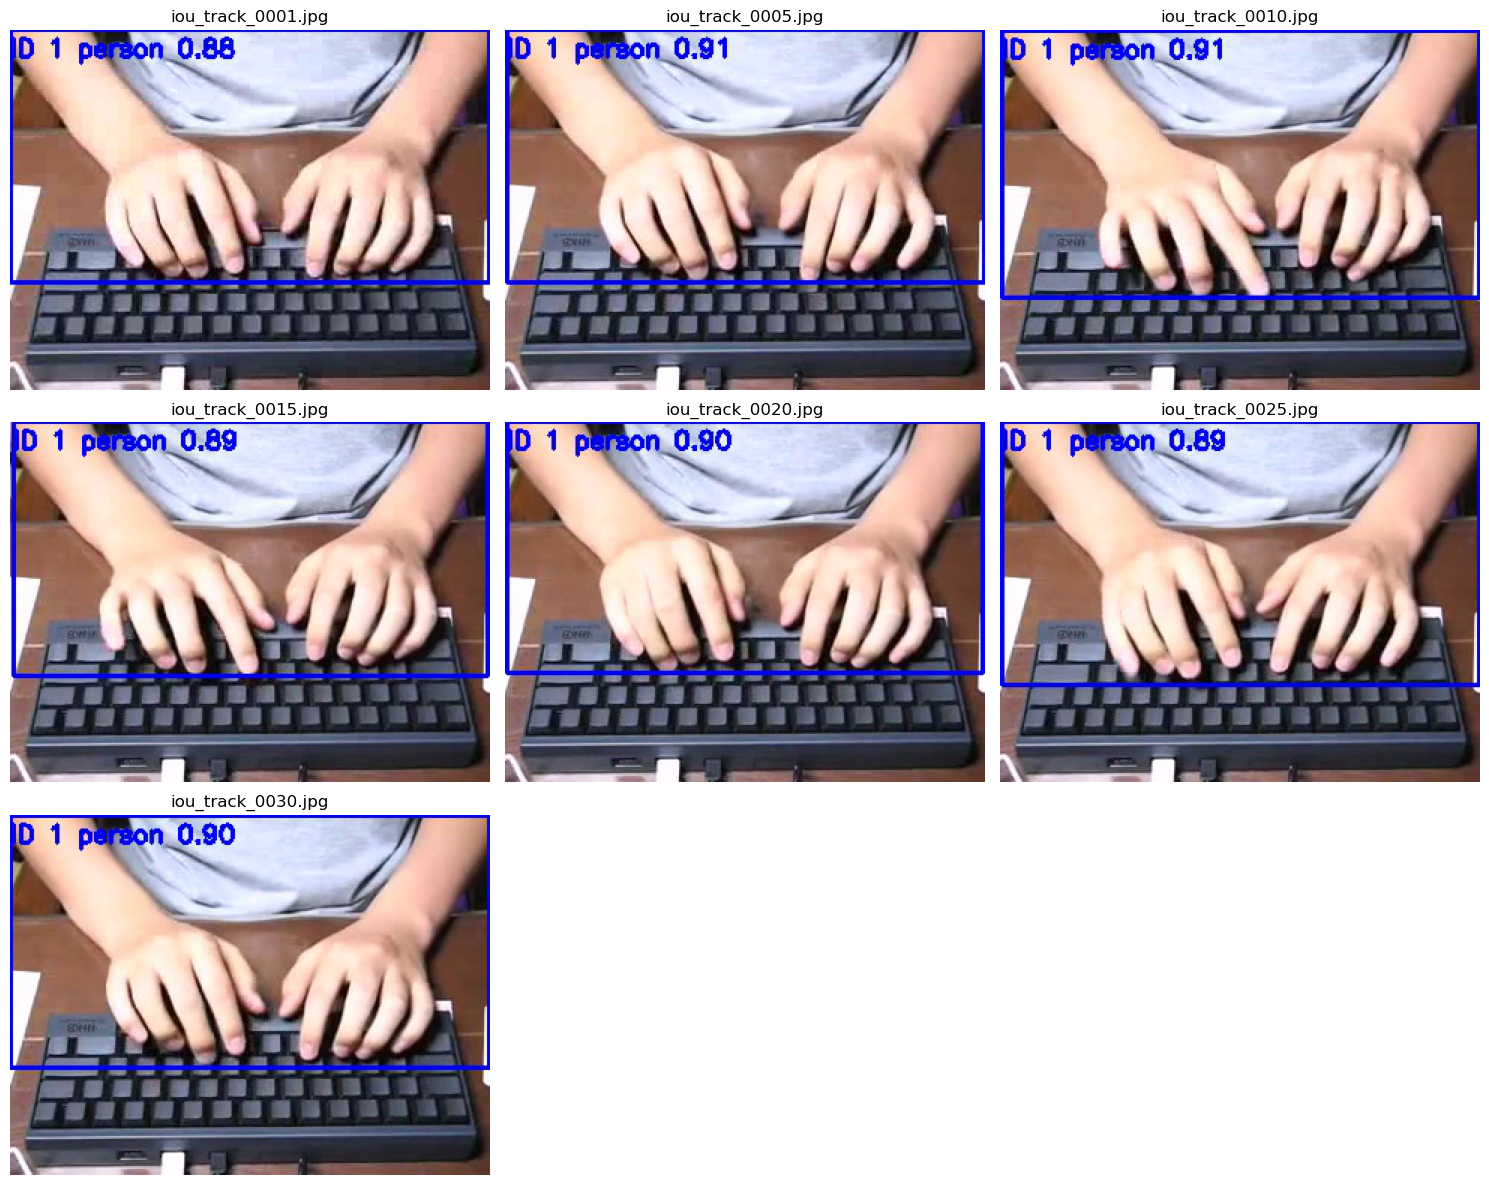


PERSON-ID SUMMARY
decoded_frames: 60
inferred_frames: 30
frames_with_person_detection: 30
detection_frame_rate: 1.0
unique_track_ids: [1]
detections_per_track_id: {'1': 30}
elapsed_seconds: 3.45
method: YOLO.predict + greedy IoU association; not ByteTrack
Output folder: C:\Users\admin\ViTPose_Action_Recognition\Notebook_2_Improved_v2\outputs\person_id_iou_pilot_v1


In [3]:
from PIL import Image
import matplotlib.pyplot as plt
preview_files=sorted(OUT_DIR.glob("iou_track_*.jpg"))
print("Preview images:",len(preview_files))
if preview_files:
    cols=min(3,len(preview_files)); rows=(len(preview_files)+cols-1)//cols
    fig,axes=plt.subplots(rows,cols,figsize=(5*cols,4*rows))
    axes=[axes] if not hasattr(axes,"flat") else list(axes.flat)
    for ax,path in zip(axes,preview_files):
        with Image.open(path) as im: ax.imshow(im.copy())
        ax.set_title(path.name); ax.axis("off")
    for ax in axes[len(preview_files):]: ax.axis("off")
    plt.tight_layout(); plt.show()
else: print("No preview images saved.")
if result_path.is_file():
    result=json.loads(result_path.read_text(encoding="utf-8"))
    print("\nPERSON-ID SUMMARY")
    for key in ["decoded_frames","inferred_frames","frames_with_person_detection","detection_frame_rate",
                "unique_track_ids","detections_per_track_id","elapsed_seconds","method"]:
        print(f"{key}: {result.get(key)}")
else: print("No successful result JSON. Inspect worker logs.")
print("Output folder:",OUT_DIR)

## Decision
Proceed to a five-video pilot only if the worker returns code 0, writes a result JSON and detection CSV, and previews show reasonable ID continuity. This is IoU association, not ByteTrack. Do not run full tracked pose extraction from an unsuccessful or unstable pilot.